In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

df = pd.read_csv("../data/feature_engineered_data.csv")

print("Rows:", len(df))
print("Columns:", len(df.columns))

Rows: 583
Columns: 29


In [2]:
df.head()

,song,artist,entry_date,exit_date,days_on_playlist,peak_position,peak_date,time_to_peak_days,observed_playlist_days,entry_position,rank_improvement,latest_position,latest_date,lifecycle_age_days,lifecycle_stage,current_decline_from_peak,retention_stability_index,is_explicit,album_type,duration_ms,total_tracks,duration_seconds,content_type,release_type,duration_category,entry_popularity,peak_popularity,latest_popularity,popularity_growth
0,0 CONFIANZA,Rvfv,2025-06-02,2025-06-23,22,23,2025-06-07,5,20,40,17,42,2025-06-23,22,Decline Phase,19,90.91,False,album,217500,20,217.50,Clean,Album,Medium (3–4 min),35,62,62,27
1,"1 de Enero, Puntacana",Rels B,2025-04-28,2025-04-28,1,45,2025-04-28,0,1,45,0,45,2025-04-28,1,New Entry,0,100.00,False,album,95000,13,95.00,Clean,Album,Short (<3 min),65,65,65,0
2,1000COSAS,Lola Indigo & Manuel Turizo,2025-03-10,2025-11-13,249,3,2025-03-10,0,245,3,0,44,2025-11-13,249,Decline Phase,41,98.39,False,single,239482,1,239.48,Clean,Single,Medium (3–4 min),65,81,72,16
3,100xCiento,Foreign Teck & Eladio Carrion & De La Ghetto,2025-04-30,2025-05-15,16,13,2025-05-11,11,11,42,29,37,2025-05-15,16,Decline Phase,24,68.75,True,single,219682,1,219.68,Explicit,Single,Medium (3–4 min),72,75,75,3
4,14 FEBREROS,Quevedo,2025-11-24,2025-11-27,4,9,2025-11-24,0,4,9,0,16,2025-11-27,4,New Entry,7,100.00,True,album,172422,18,172.42,Explicit,Album,Short (<3 min),63,68,68,5


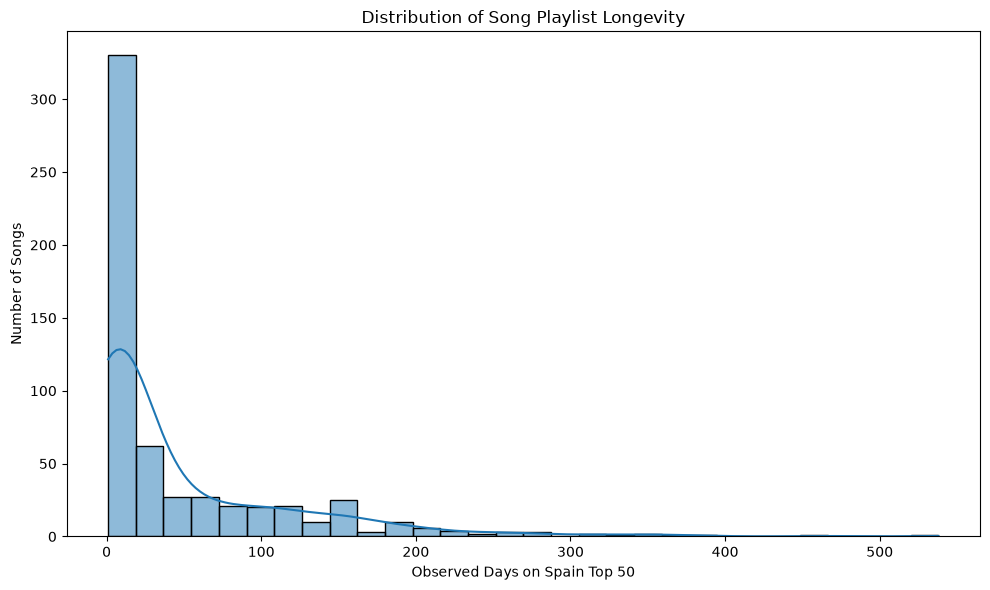

In [3]:
plt.figure(figsize=(10, 6))

sns.histplot(
    df["observed_playlist_days"],
    bins=30,
    kde=True
)

plt.title("Distribution of Song Playlist Longevity")
plt.xlabel("Observed Days on Spain Top 50")
plt.ylabel("Number of Songs")

plt.tight_layout()
plt.show()

In [4]:
print(df.head())

                    song                                        artist  \
0            0 CONFIANZA                                          Rvfv   
1  1 de Enero, Puntacana                                        Rels B   
2              1000COSAS                   Lola Indigo & Manuel Turizo   
3             100xCiento  Foreign Teck & Eladio Carrion & De La Ghetto   
4            14 FEBREROS                                       Quevedo   

   entry_date   exit_date  days_on_playlist  peak_position   peak_date  \
0  2025-06-02  2025-06-23                22             23  2025-06-07   
1  2025-04-28  2025-04-28                 1             45  2025-04-28   
2  2025-03-10  2025-11-13               249              3  2025-03-10   
3  2025-04-30  2025-05-15                16             13  2025-05-11   
4  2025-11-24  2025-11-27                 4              9  2025-11-24   

   time_to_peak_days  observed_playlist_days  entry_position  \
0                  5                      20  

In [5]:
print(df.columns.tolist())

['song', 'artist', 'entry_date', 'exit_date', 'days_on_playlist', 'peak_position', 'peak_date', 'time_to_peak_days', 'observed_playlist_days', 'entry_position', 'rank_improvement', 'latest_position', 'latest_date', 'lifecycle_age_days', 'lifecycle_stage', 'current_decline_from_peak', 'retention_stability_index', 'is_explicit', 'album_type', 'duration_ms', 'total_tracks', 'duration_seconds', 'content_type', 'release_type', 'duration_category', 'entry_popularity', 'peak_popularity', 'latest_popularity', 'popularity_growth']


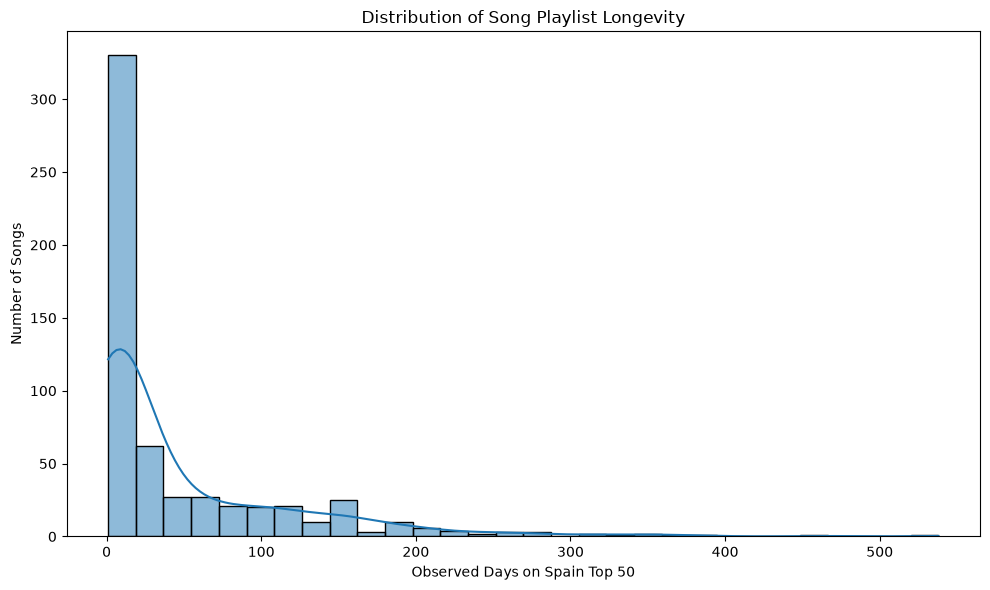

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.histplot(
    df["observed_playlist_days"],
    bins=30,
    kde=True
)

plt.title("Distribution of Song Playlist Longevity")
plt.xlabel("Observed Days on Spain Top 50")
plt.ylabel("Number of Songs")

plt.tight_layout()
plt.show()

In [7]:
print("Average observed days:",
      round(df["observed_playlist_days"].mean(), 2))

print("Median observed days:",
      df["observed_playlist_days"].median())

print("Minimum observed days:",
      df["observed_playlist_days"].min())

print("Maximum observed days:",
      df["observed_playlist_days"].max())

Average observed days: 47.6
Median observed days: 13.0
Minimum observed days: 1
Maximum observed days: 538


In [8]:
print(
    df["observed_playlist_days"]
    .quantile([0.25, 0.50, 0.75])
)

0.25     4.0
0.50    13.0
0.75    66.0
Name: observed_playlist_days, dtype: float64


In [9]:
stage_counts = (
    df["lifecycle_stage"]
    .value_counts()
    .reindex([
        "New Entry",
        "Growth Phase",
        "Peak Phase",
        "Mature Phase",
        "Decline Phase"
    ])
)

print(stage_counts)

lifecycle_stage
New Entry        233
Growth Phase      31
Peak Phase         9
Mature Phase      11
Decline Phase    299
Name: count, dtype: int64


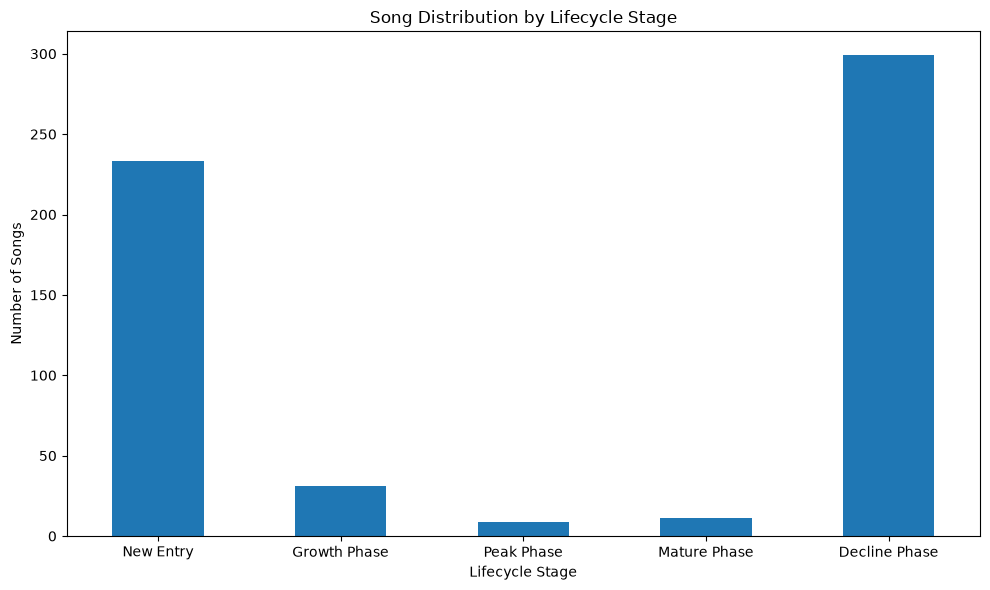

In [10]:
plt.figure(figsize=(10, 6))

stage_counts.plot(kind="bar")

plt.title("Song Distribution by Lifecycle Stage")
plt.xlabel("Lifecycle Stage")
plt.ylabel("Number of Songs")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [11]:
stage_percentage = (
    df["lifecycle_stage"]
    .value_counts(normalize=True)
    .reindex([
        "New Entry",
        "Growth Phase",
        "Peak Phase",
        "Mature Phase",
        "Decline Phase"
    ])
    .mul(100)
    .round(2)
)

print(stage_percentage)

lifecycle_stage
New Entry        39.97
Growth Phase      5.32
Peak Phase        1.54
Mature Phase      1.89
Decline Phase    51.29
Name: proportion, dtype: float64


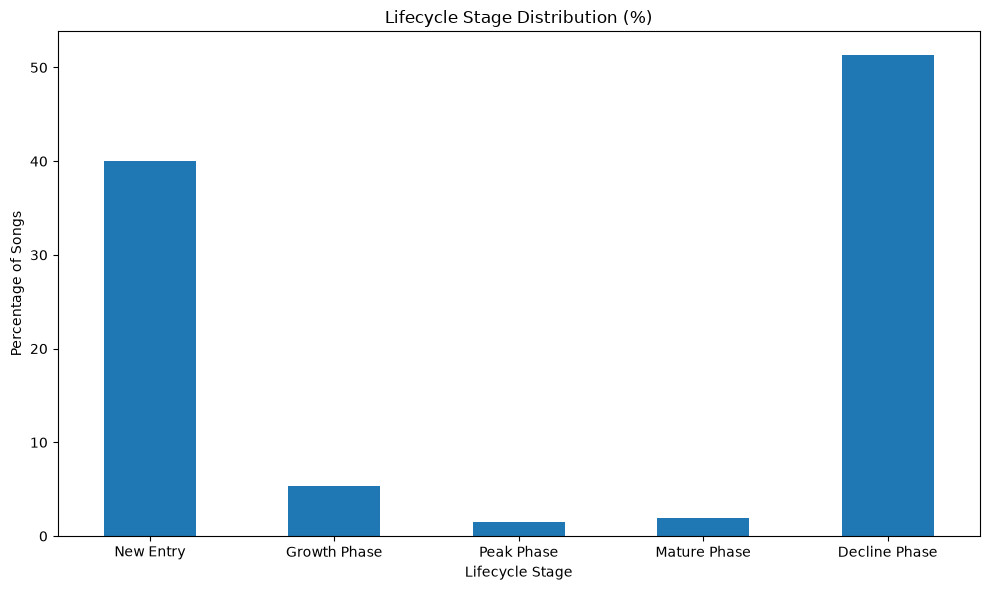

In [12]:
plt.figure(figsize=(10, 6))

stage_percentage.plot(kind="bar")

plt.title("Lifecycle Stage Distribution (%)")
plt.xlabel("Lifecycle Stage")
plt.ylabel("Percentage of Songs")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [13]:
explicit_lifecycle = (
    df.groupby("content_type")
      .agg(
          songs=("song", "count"),
          avg_observed_days=("observed_playlist_days", "mean"),
          avg_lifecycle_days=("days_on_playlist", "mean"),
          avg_time_to_peak=("time_to_peak_days", "mean"),
          avg_peak_position=("peak_position", "mean"),
          avg_stability=("retention_stability_index", "mean"),
          avg_popularity_growth=("popularity_growth", "mean")
      )
      .round(2)
)

print(explicit_lifecycle)

              songs  avg_observed_days  avg_lifecycle_days  avg_time_to_peak  \
content_type                                                                   
Clean           329              49.65               58.65              9.62   
Explicit        254              44.94               53.54              9.38   

              avg_peak_position  avg_stability  avg_popularity_growth  
content_type                                                           
Clean                     22.22          91.46                  14.73  
Explicit                  21.54          92.13                  22.32  


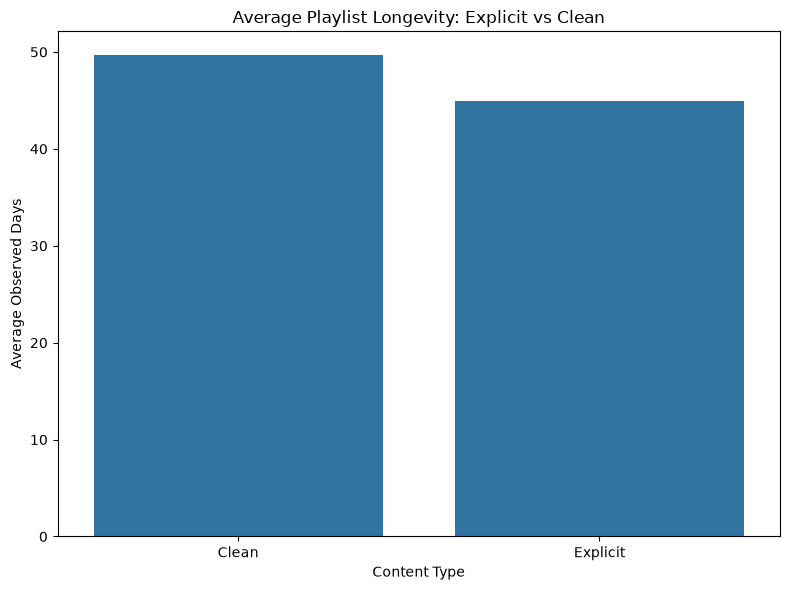

In [14]:
plt.figure(figsize=(8, 6))

sns.barplot(
    data=df,
    x="content_type",
    y="observed_playlist_days",
    estimator="mean",
    errorbar=None
)

plt.title("Average Playlist Longevity: Explicit vs Clean")
plt.xlabel("Content Type")
plt.ylabel("Average Observed Days")

plt.tight_layout()
plt.show()

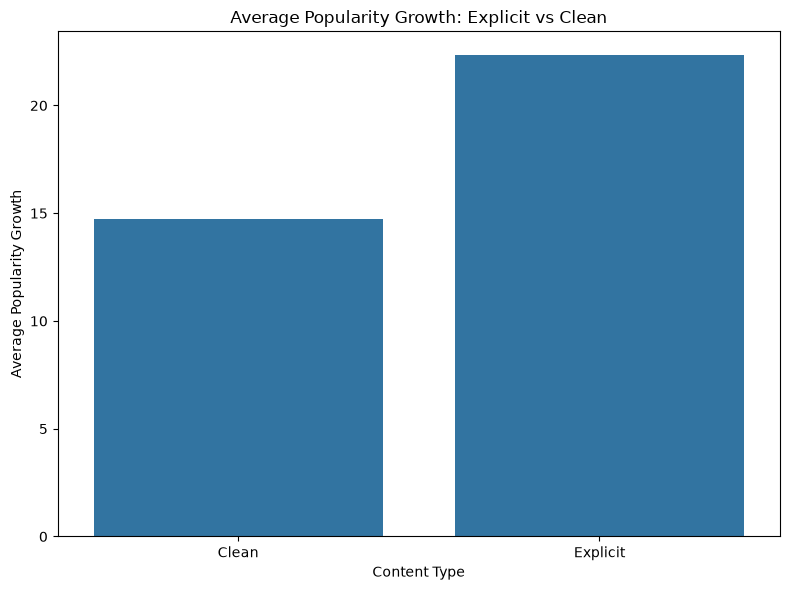

In [15]:
plt.figure(figsize=(8, 6))

sns.barplot(
    data=df,
    x="content_type",
    y="popularity_growth",
    estimator="mean",
    errorbar=None
)

plt.title("Average Popularity Growth: Explicit vs Clean")
plt.xlabel("Content Type")
plt.ylabel("Average Popularity Growth")

plt.tight_layout()
plt.show()

In [16]:
release_comparison = (
    df.groupby("release_type")
      .agg(
          songs=("song", "count"),
          avg_observed_days=("observed_playlist_days", "mean"),
          avg_lifecycle_days=("days_on_playlist", "mean"),
          avg_time_to_peak=("time_to_peak_days", "mean"),
          avg_peak_position=("peak_position", "mean"),
          avg_stability=("retention_stability_index", "mean"),
          avg_popularity_growth=("popularity_growth", "mean")
      )
      .round(2)
)

print(release_comparison)

              songs  avg_observed_days  avg_lifecycle_days  avg_time_to_peak  \
release_type                                                                   
Album           293              38.05               48.19              8.61   
Single          290              57.25               64.74             10.42   

              avg_peak_position  avg_stability  avg_popularity_growth  
release_type                                                           
Album                     22.93          92.03                  22.69  
Single                    20.90          91.47                  13.34  


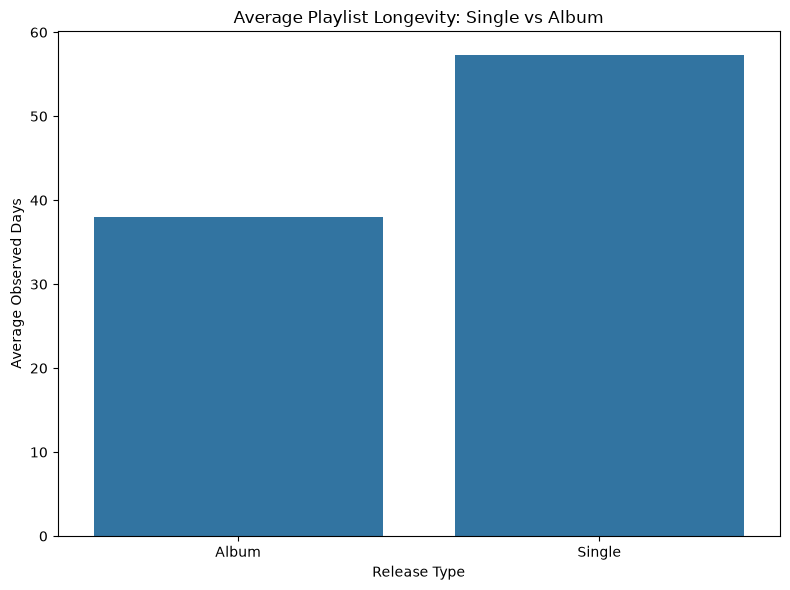

In [17]:
plt.figure(figsize=(8, 6))

sns.barplot(
    data=df,
    x="release_type",
    y="observed_playlist_days",
    estimator="mean",
    errorbar=None
)

plt.title("Average Playlist Longevity: Single vs Album")
plt.xlabel("Release Type")
plt.ylabel("Average Observed Days")

plt.tight_layout()
plt.show()

In [18]:
duration_comparison = (
    df.groupby("duration_category")
      .agg(
          songs=("song", "count"),
          avg_observed_days=("observed_playlist_days", "mean"),
          avg_lifecycle_days=("days_on_playlist", "mean"),
          avg_peak_position=("peak_position", "mean"),
          avg_stability=("retention_stability_index", "mean")
      )
      .reindex([
          "Short (<3 min)",
          "Medium (3–4 min)",
          "Long (>4 min)"
      ])
      .round(2)
)

print(duration_comparison)

                   songs  avg_observed_days  avg_lifecycle_days  \
duration_category                                                 
Short (<3 min)       231              44.42               53.55   
Medium (3–4 min)     273              52.07               61.49   
Long (>4 min)         79              41.46               47.33   

                   avg_peak_position  avg_stability  
duration_category                                    
Short (<3 min)                 23.33          91.66  
Medium (3–4 min)               20.75          92.11  
Long (>4 min)                  21.81          90.79  


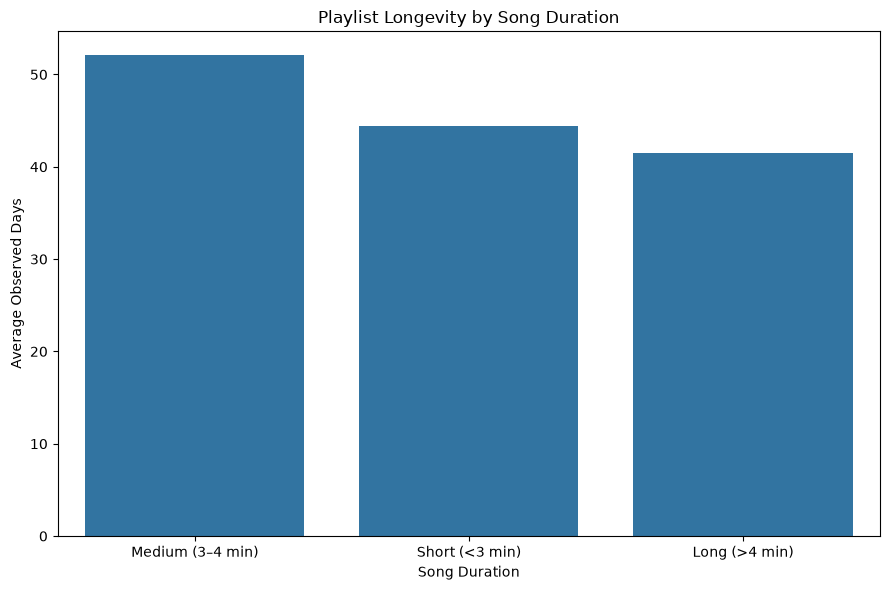

In [19]:
plt.figure(figsize=(9, 6))

sns.barplot(
    data=df,
    x="duration_category",
    y="observed_playlist_days",
    estimator="mean",
    errorbar=None
)

plt.title("Playlist Longevity by Song Duration")
plt.xlabel("Song Duration")
plt.ylabel("Average Observed Days")

plt.tight_layout()
plt.show()

In [20]:
album_size_analysis = (
    df.groupby("total_tracks")
      .agg(
          songs=("song", "count"),
          avg_observed_days=("observed_playlist_days", "mean"),
          avg_lifecycle_days=("days_on_playlist", "mean"),
          avg_stability=("retention_stability_index", "mean"),
          avg_peak_position=("peak_position", "mean")
      )
      .sort_index()
      .round(2)
)

print(album_size_analysis)

              songs  avg_observed_days  avg_lifecycle_days  avg_stability  \
total_tracks                                                                
1               259              59.88               68.16          90.94   
2                10              49.40               51.30          92.11   
3                 4              71.00               71.25          99.78   
5                 9              22.67               23.11          99.02   
6                 8              13.88               14.38          95.19   
7                 9              32.56               38.56          85.09   
8                 3             129.00              150.33          93.75   
9                16              50.25               79.50          83.01   
10               20              29.95               34.40          83.86   
11                2             153.00              170.50          92.10   
12                9               7.67               13.22          93.46   

In [21]:
def album_size_category(tracks):
    if tracks == 1:
        return "1 Track"
    elif tracks <= 7:
        return "2–7 Tracks"
    elif tracks <= 12:
        return "8–12 Tracks"
    else:
        return "13+ Tracks"

df["album_size_category"] = (
    df["total_tracks"]
    .apply(album_size_category)
)

In [22]:
album_size_comparison = (
    df.groupby("album_size_category")
      .agg(
          songs=("song", "count"),
          avg_observed_days=("observed_playlist_days", "mean"),
          avg_lifecycle_days=("days_on_playlist", "mean"),
          avg_stability=("retention_stability_index", "mean")
      )
      .reindex([
          "1 Track",
          "2–7 Tracks",
          "8–12 Tracks",
          "13+ Tracks"
      ])
      .round(2)
)

print(album_size_comparison)

                     songs  avg_observed_days  avg_lifecycle_days  \
album_size_category                                                 
1 Track                259              59.88               68.16   
2–7 Tracks              40              34.65               36.70   
8–12 Tracks             50              43.30               57.42   
13+ Tracks             234              37.14               46.59   

                     avg_stability  
album_size_category                 
1 Track                      90.94  
2–7 Tracks                   93.47  
8–12 Tracks                  86.24  
13+ Tracks                   93.53  


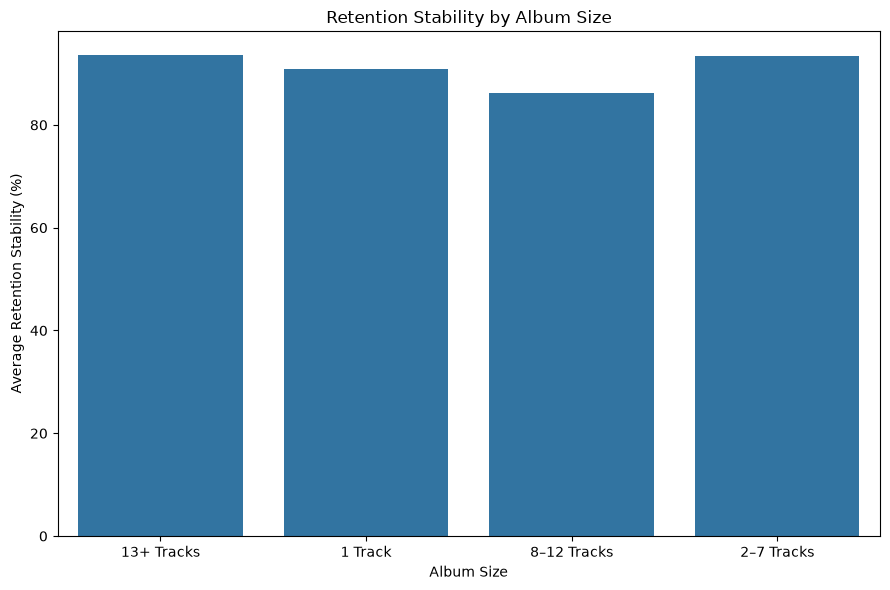

In [23]:
plt.figure(figsize=(9, 6))

sns.barplot(
    data=df,
    x="album_size_category",
    y="retention_stability_index",
    estimator="mean",
    errorbar=None
)

plt.title("Retention Stability by Album Size")
plt.xlabel("Album Size")
plt.ylabel("Average Retention Stability (%)")

plt.tight_layout()
plt.show()

In [24]:
df["entry_date"] = pd.to_datetime(df["entry_date"])
df["exit_date"] = pd.to_datetime(df["exit_date"])

In [25]:
monthly_entries = (
    df.groupby(df["entry_date"].dt.to_period("M"))
      .size()
      .reset_index(name="entries")
)

monthly_entries["month"] = (
    monthly_entries["entry_date"]
    .astype(str)
)

print(monthly_entries.head(10))

  entry_date  entries    month
0    2024-05       64  2024-05
1    2024-06       20  2024-06
2    2024-07       20  2024-07
3    2024-08       28  2024-08
4    2024-09       25  2024-09
5    2024-10       40  2024-10
6    2024-11       21  2024-11
7    2024-12       37  2024-12
8    2025-01       28  2025-01
9    2025-02       16  2025-02


In [26]:
monthly_exits = (
    df.groupby(df["exit_date"].dt.to_period("M"))
      .size()
      .reset_index(name="exits")
)

monthly_exits["month"] = (
    monthly_exits["exit_date"]
    .astype(str)
)

print(monthly_exits.head(10))

  exit_date  exits    month
0   2024-05     10  2024-05
1   2024-06     21  2024-06
2   2024-07     20  2024-07
3   2024-08     17  2024-08
4   2024-09     30  2024-09
5   2024-10     34  2024-10
6   2024-11     23  2024-11
7   2024-12     35  2024-12
8   2025-01     36  2025-01
9   2025-02     16  2025-02


In [27]:
print(monthly_entries.head(10))

  entry_date  entries    month
0    2024-05       64  2024-05
1    2024-06       20  2024-06
2    2024-07       20  2024-07
3    2024-08       28  2024-08
4    2024-09       25  2024-09
5    2024-10       40  2024-10
6    2024-11       21  2024-11
7    2024-12       37  2024-12
8    2025-01       28  2025-01
9    2025-02       16  2025-02


In [28]:
monthly_rotation = pd.merge(
    monthly_entries[["month", "entries"]],
    monthly_exits[["month", "exits"]],
    on="month",
    how="outer"
).fillna(0)

monthly_rotation["entries"] = monthly_rotation["entries"].astype(int)
monthly_rotation["exits"] = monthly_rotation["exits"].astype(int)

monthly_rotation = monthly_rotation.sort_values("month")

print(monthly_rotation)

      month  entries  exits
0   2024-05       64     10
1   2024-06       20     21
2   2024-07       20     20
3   2024-08       28     17
4   2024-09       25     30
5   2024-10       40     34
6   2024-11       21     23
7   2024-12       37     35
8   2025-01       28     36
9   2025-02       16     16
10  2025-03       30     28
11  2025-04       51     38
12  2025-05       22     33
13  2025-06       29     31
14  2025-07       25     27
15  2025-08       29     31
16  2025-09       22     21
17  2025-10       21     28
18  2025-11       55    104


In [29]:
monthly_rotation["churn_rate"] = (
    (monthly_rotation["entries"] + monthly_rotation["exits"])
    / (2 * 50)
) * 100

monthly_rotation["churn_rate"] = monthly_rotation["churn_rate"].round(2)

print(monthly_rotation)

      month  entries  exits  churn_rate
0   2024-05       64     10        74.0
1   2024-06       20     21        41.0
2   2024-07       20     20        40.0
3   2024-08       28     17        45.0
4   2024-09       25     30        55.0
5   2024-10       40     34        74.0
6   2024-11       21     23        44.0
7   2024-12       37     35        72.0
8   2025-01       28     36        64.0
9   2025-02       16     16        32.0
10  2025-03       30     28        58.0
11  2025-04       51     38        89.0
12  2025-05       22     33        55.0
13  2025-06       29     31        60.0
14  2025-07       25     27        52.0
15  2025-08       29     31        60.0
16  2025-09       22     21        43.0
17  2025-10       21     28        49.0
18  2025-11       55    104       159.0


In [30]:
average_churn = monthly_rotation["churn_rate"].mean()

print("Average monthly churn rate:",
      round(average_churn, 2), "%")

Average monthly churn rate: 61.37 %


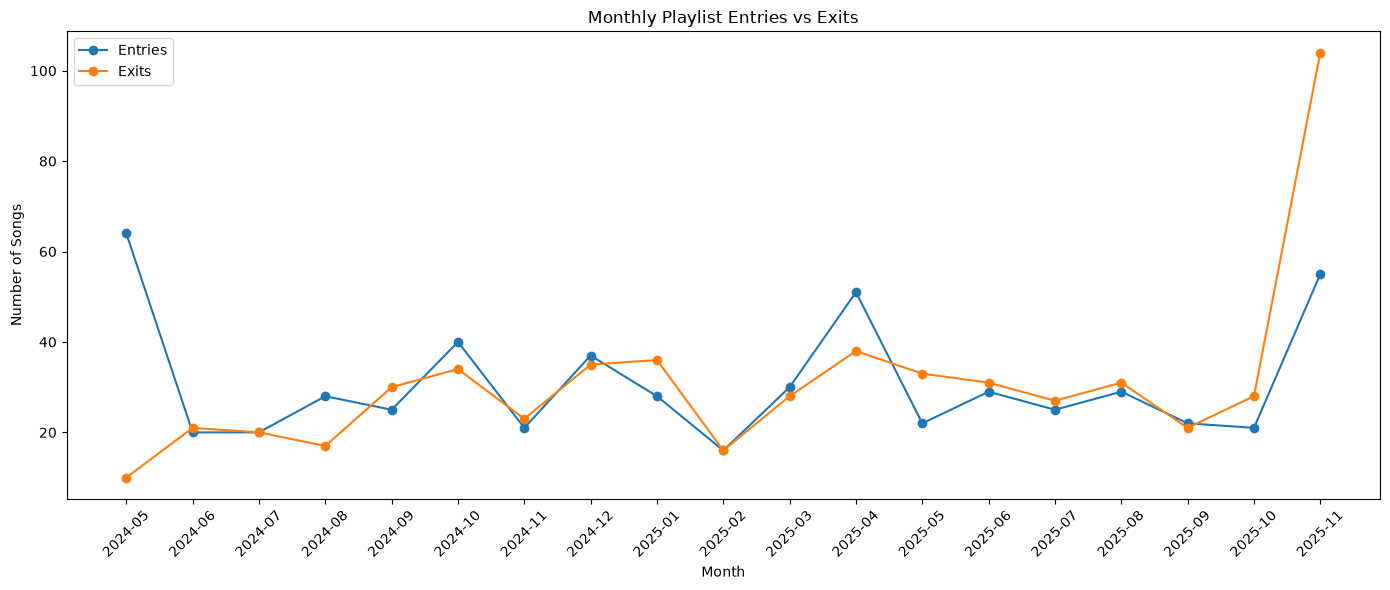

In [31]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_rotation["month"],
    monthly_rotation["entries"],
    marker="o",
    label="Entries"
)

plt.plot(
    monthly_rotation["month"],
    monthly_rotation["exits"],
    marker="o",
    label="Exits"
)

plt.title("Monthly Playlist Entries vs Exits")
plt.xlabel("Month")
plt.ylabel("Number of Songs")
plt.xticks(rotation=45)
plt.legend()

plt.tight_layout()
plt.show()

In [32]:
highest_churn = monthly_rotation.loc[
    monthly_rotation["churn_rate"].idxmax()
]

lowest_churn = monthly_rotation.loc[
    monthly_rotation["churn_rate"].idxmin()
]

print("Highest churn month:")
print(highest_churn)

print("\nLowest churn month:")
print(lowest_churn)

Highest churn month:
month         2025-11
entries            55
exits             104
churn_rate      159.0
Name: 18, dtype: object

Lowest churn month:
month         2025-02
entries            16
exits              16
churn_rate       32.0
Name: 9, dtype: object


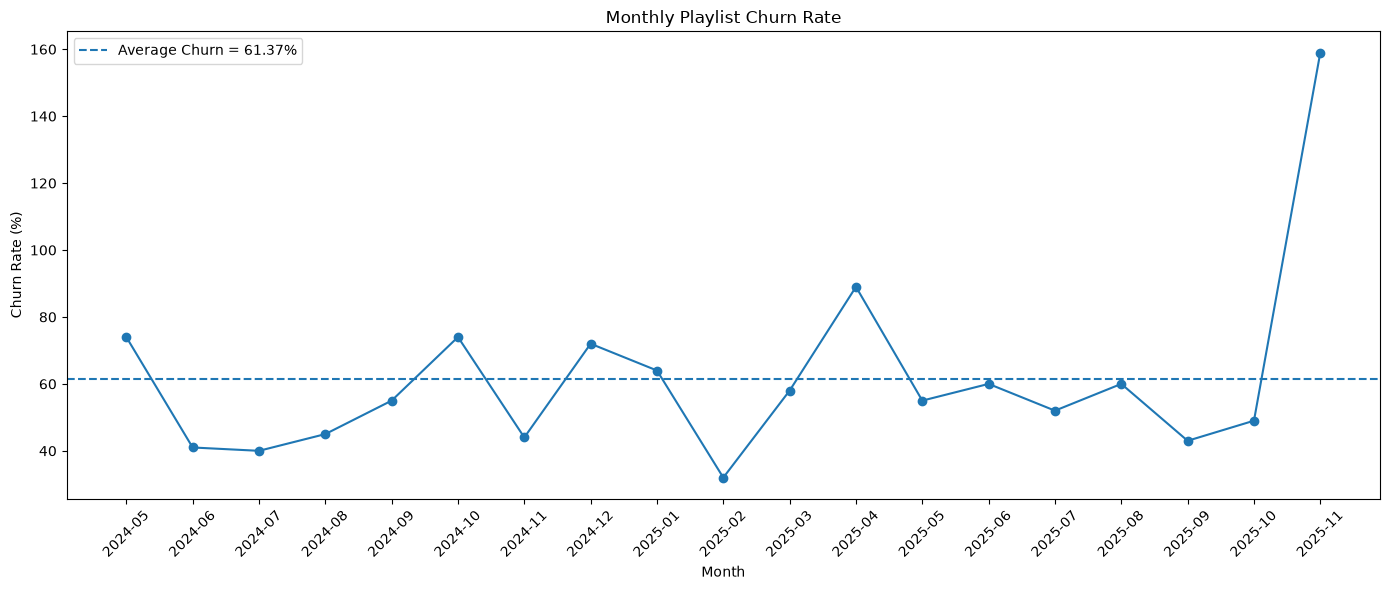

In [33]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_rotation["month"],
    monthly_rotation["churn_rate"],
    marker="o"
)

plt.axhline(
    average_churn,
    linestyle="--",
    label=f"Average Churn = {average_churn:.2f}%"
)

plt.title("Monthly Playlist Churn Rate")
plt.xlabel("Month")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=45)
plt.legend()

plt.tight_layout()
plt.show()

In [34]:
lifecycle_popularity = (
    df.groupby("lifecycle_stage")
      .agg(
          songs=("song", "count"),
          avg_entry_popularity=("entry_popularity", "mean"),
          avg_peak_popularity=("peak_popularity", "mean"),
          avg_latest_popularity=("latest_popularity", "mean"),
          avg_popularity_growth=("popularity_growth", "mean")
      )
      .reindex([
          "New Entry",
          "Growth Phase",
          "Peak Phase",
          "Mature Phase",
          "Decline Phase"
      ])
      .round(2)
)

print(lifecycle_popularity)

                 songs  avg_entry_popularity  avg_peak_popularity  \
lifecycle_stage                                                     
New Entry          233                 49.77                62.59   
Growth Phase        31                 72.87                77.45   
Peak Phase           9                 66.67                82.89   
Mature Phase        11                 65.00                79.91   
Decline Phase      299                 59.02                82.70   

                 avg_latest_popularity  avg_popularity_growth  
lifecycle_stage                                                
New Entry                        62.58                  12.82  
Growth Phase                     76.74                   4.58  
Peak Phase                       82.89                  16.22  
Mature Phase                     79.64                  14.91  
Decline Phase                    79.53                  23.68  


In [35]:
popularity_plot = (
    lifecycle_popularity
    .reset_index()
    .melt(
        id_vars="lifecycle_stage",
        value_vars=[
            "avg_entry_popularity",
            "avg_peak_popularity",
            "avg_latest_popularity"
        ],
        var_name="popularity_type",
        value_name="popularity"
    )
)

popularity_plot["popularity_type"] = (
    popularity_plot["popularity_type"]
    .replace({
        "avg_entry_popularity": "Entry Popularity",
        "avg_peak_popularity": "Peak Popularity",
        "avg_latest_popularity": "Latest Popularity"
    })
)

print(popularity_plot)

   lifecycle_stage    popularity_type  popularity
0        New Entry   Entry Popularity       49.77
1     Growth Phase   Entry Popularity       72.87
2       Peak Phase   Entry Popularity       66.67
3     Mature Phase   Entry Popularity       65.00
4    Decline Phase   Entry Popularity       59.02
5        New Entry    Peak Popularity       62.59
6     Growth Phase    Peak Popularity       77.45
7       Peak Phase    Peak Popularity       82.89
8     Mature Phase    Peak Popularity       79.91
9    Decline Phase    Peak Popularity       82.70
10       New Entry  Latest Popularity       62.58
11    Growth Phase  Latest Popularity       76.74
12      Peak Phase  Latest Popularity       82.89
13    Mature Phase  Latest Popularity       79.64
14   Decline Phase  Latest Popularity       79.53


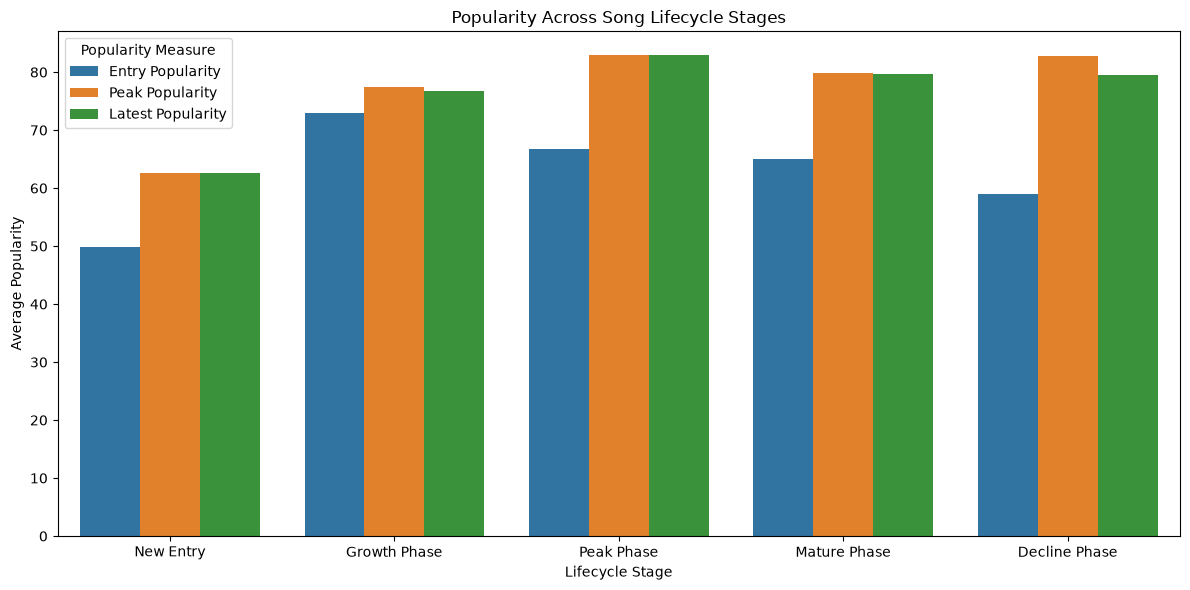

In [36]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=popularity_plot,
    x="lifecycle_stage",
    y="popularity",
    hue="popularity_type"
)

plt.title("Popularity Across Song Lifecycle Stages")
plt.xlabel("Lifecycle Stage")
plt.ylabel("Average Popularity")

plt.xticks(rotation=0)
plt.legend(title="Popularity Measure")

plt.tight_layout()
plt.show()

In [37]:
rank_analysis = (
    df.groupby("lifecycle_stage")
      .agg(
          songs=("song", "count"),
          avg_entry_position=("entry_position", "mean"),
          avg_peak_position=("peak_position", "mean"),
          avg_rank_improvement=("rank_improvement", "mean"),
          avg_decline_from_peak=("current_decline_from_peak", "mean"),
          avg_stability=("retention_stability_index", "mean")
      )
      .reindex([
          "New Entry",
          "Growth Phase",
          "Peak Phase",
          "Mature Phase",
          "Decline Phase"
      ])
      .round(2)
)

print(rank_analysis)

                 songs  avg_entry_position  avg_peak_position  \
lifecycle_stage                                                 
New Entry          233               31.92              30.55   
Growth Phase        31               48.58              39.65   
Peak Phase           9               14.67               1.89   
Mature Phase        11               42.09               7.91   
Decline Phase      299               26.96              14.47   

                 avg_rank_improvement  avg_decline_from_peak  avg_stability  
lifecycle_stage                                                              
New Entry                        1.37                   8.04          96.73  
Growth Phase                     8.94                   5.39          71.31  
Peak Phase                      12.78                   3.67         100.00  
Mature Phase                    34.18                   8.73          92.13  
Decline Phase                   12.48                  31.21          89.73 

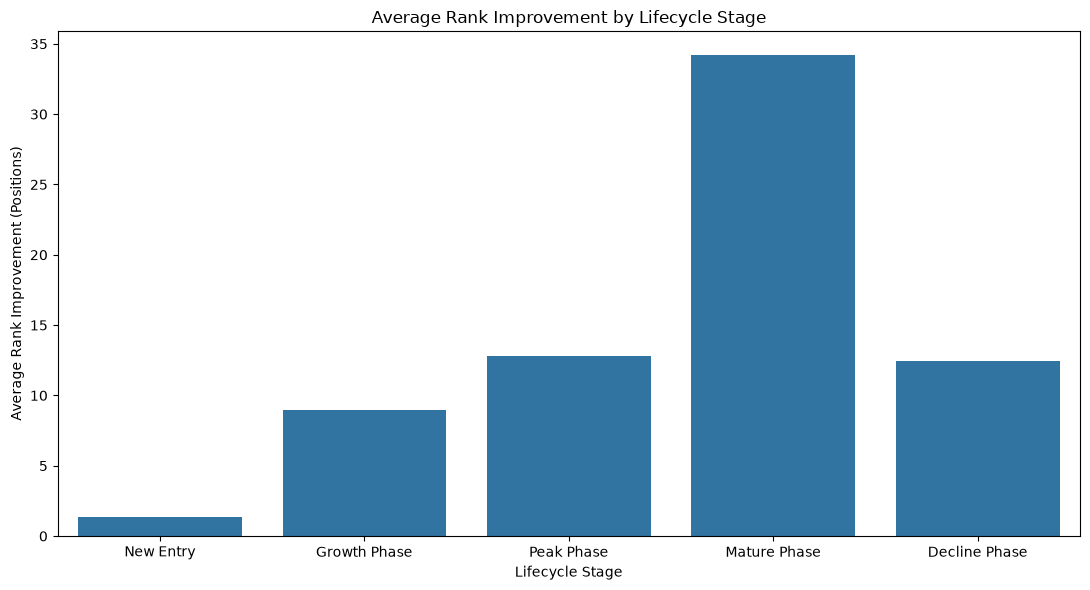

In [38]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=rank_analysis.reset_index(),
    x="lifecycle_stage",
    y="avg_rank_improvement"
)

plt.title("Average Rank Improvement by Lifecycle Stage")
plt.xlabel("Lifecycle Stage")
plt.ylabel("Average Rank Improvement (Positions)")

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [39]:
print("========== FINAL EDA SUMMARY ==========")

print("Total Songs:", df["song"].nunique())
print("Total Playlist Records:", len(df))

print(
    "Average Lifecycle:",
    round(df["days_on_playlist"].mean(), 2),
    "days"
)

print(
    "Average Observed Playlist Days:",
    round(df["observed_playlist_days"].mean(), 2),
    "days"
)

print(
    "Average Time to Peak:",
    round(df["time_to_peak_days"].mean(), 2),
    "days"
)

print(
    "Average Rank Improvement:",
    round(df["rank_improvement"].mean(), 2),
    "positions"
)

print(
    "Average Stability:",
    round(df["retention_stability_index"].mean(), 2)
)

print(
    "Average Popularity Growth:",
    round(df["popularity_growth"].mean(), 2)
)

print(
    "Average Monthly Churn:",
    round(average_churn, 2),
    "%"
)

print(
    "Highest Churn Month:",
    highest_churn["month"],
    "(",
    highest_churn["churn_rate"],
    "%)"
)

print(
    "Lowest Churn Month:",
    lowest_churn["month"],
    "(",
    lowest_churn["churn_rate"],
    "%)"
)

print("========================================")

========== FINAL EDA SUMMARY ==========
Total Songs: 545
Total Playlist Records: 583
Average Lifecycle: 56.42 days
Average Observed Playlist Days: 47.6 days
Average Time to Peak: 9.51 days
Average Rank Improvement: 8.27 positions
Average Stability: 91.75
Average Popularity Growth: 18.04
Average Monthly Churn: 61.37 %
Highest Churn Month: 2025-11 ( 159.0 %)
Lowest Churn Month: 2025-02 ( 32.0 %)
